# Análisis exploratorio de los patrones de sueño en estudiantes universitarios

**Asignatura:** Maestría en Inteligencia Artificial Aplicada
**Estudiante:** Alexandra Yamiletti Zuñiga Huanca  

En el contexto universitario, los estudiantes suelen combinar sus actividades académicas con diversos hábitos y rutinas diarias que podrían influir en sus patrones de sueño. Sin embargo, no siempre se conoce cómo factores como las horas de estudio, el tiempo frente a pantallas, el consumo de cafeína y la actividad física se relacionan con la duración y calidad del descanso. Esta falta de información dificulta identificar qué hábitos presentan mayores asociaciones con el sueño de los estudiantes.

Ante esta situación, se plantea analizar el conjunto de datos Student Sleep Patterns mediante técnicas de análisis exploratorio de datos, con el propósito de identificar patrones, comparar comportamientos y examinar las posibles relaciones entre los hábitos académicos, el estilo de vida y el descanso de los estudiantes universitarios.


**Pregunta de análisis:** ¿Qué relaciones existen entre la duración y calidad del sueño y los hábitos académicos y de estilo de vida registrados en el conjunto de datos?

> **Nota:** los registros son datos sintéticos descargados de Kaggle. 

## 1. Configuración del entorno y bibliotecas

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import polars as pl

import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

from bokeh.io import output_notebook
from bokeh.models import ColumnDataSource, HoverTool
from bokeh.plotting import figure, show

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
output_notebook()

print("Bibliotecas cargadas correctamente.")

Loading BokehJS ...

Bibliotecas cargadas correctamente.


## 2. Carga y descripción del conjunto de datos

El archivo CSV se busca en las ubicaciones habituales del proyecto: la carpeta `data` junto al notebook o un nivel por encima de ella. Se conserva una única ruta (`DATA_PATH`) para utilizarla tanto con Pandas como con Polars.

In [2]:
possible_paths = [
    Path("data/student_sleep_patterns.csv"),
    Path("../data/student_sleep_patterns.csv"),
]

DATA_PATH = next((path for path in possible_paths if path.exists()), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        "No se encontró student_sleep_patterns.csv. "
        "Coloca el archivo en la carpeta data del proyecto."
    )

df = pd.read_csv(DATA_PATH)

print(f"Archivo cargado: {DATA_PATH}")
print(f"Registros: {df.shape[0]}")
print(f"Columnas: {df.shape[1]}")
display(df.head())

Archivo cargado: ..\data\student_sleep_patterns.csv
Registros: 500
Columnas: 14


,Student_ID,Age,Gender,University_Year,Sleep_Duration,Study_Hours,Screen_Time,Caffeine_Intake,Physical_Activity,Sleep_Quality,Weekday_Sleep_Start,Weekend_Sleep_Start,Weekday_Sleep_End,Weekend_Sleep_End
0,1,24,Other,2nd Year,7.7,7.9,3.4,2,37,10,14.16,4.05,7.41,7.06
1,2,21,Male,1st Year,6.3,6.0,1.9,5,74,2,8.73,7.10,8.21,10.21
2,3,22,Male,4th Year,5.1,6.7,3.9,5,53,5,20.00,20.47,6.88,10.92
3,4,24,Other,4th Year,6.3,8.6,2.8,4,55,9,19.82,4.08,6.69,9.42
4,5,20,Male,4th Year,4.7,2.7,2.7,0,85,3,20.98,6.12,8.98,9.01


### 2.1 Estructura y tipos de datos

Se revisan las primeras observaciones, los tipos de datos y los estadísticos descriptivos iniciales para conocer la estructura del archivo.

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 14 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Student_ID           500 non-null    int64  
 1   Age                  500 non-null    int64  
 2   Gender               500 non-null    str    
 3   University_Year      500 non-null    str    
 4   Sleep_Duration       500 non-null    float64
 5   Study_Hours          500 non-null    float64
 6   Screen_Time          500 non-null    float64
 7   Caffeine_Intake      500 non-null    int64  
 8   Physical_Activity    500 non-null    int64  
 9   Sleep_Quality        500 non-null    int64  
 10  Weekday_Sleep_Start  500 non-null    float64
 11  Weekend_Sleep_Start  500 non-null    float64
 12  Weekday_Sleep_End    500 non-null    float64
 13  Weekend_Sleep_End    500 non-null    float64
dtypes: float64(7), int64(5), str(2)
memory usage: 54.8 KB


In [4]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Student_ID,500.0,NaN,NaN,NaN,250.5,144.481833,1.0,125.75,250.5,375.25,500.0
Age,500.0,NaN,NaN,NaN,21.536,2.33315,18.0,20.0,21.0,24.0,25.0
Gender,500,3,Male,186,NaN,NaN,NaN,NaN,NaN,NaN,NaN
University_Year,500,4,3rd Year,132,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sleep_Duration,500.0,NaN,NaN,NaN,6.4724,1.485764,4.0,5.1,6.5,7.8,9.0
Study_Hours,500.0,NaN,NaN,NaN,5.9816,3.475725,0.1,2.9,6.05,8.8,12.0
Screen_Time,500.0,NaN,NaN,NaN,2.525,0.859414,1.0,1.8,2.6,3.3,4.0
Caffeine_Intake,500.0,NaN,NaN,NaN,2.462,1.682325,0.0,1.0,2.0,4.0,5.0
Physical_Activity,500.0,NaN,NaN,NaN,62.342,35.191674,0.0,32.75,62.5,93.25,120.0
Sleep_Quality,500.0,NaN,NaN,NaN,5.362,2.967249,1.0,3.0,5.0,8.0,10.0


## 3. Limpieza y validación de datos

Antes de transformar o analizar las variables, se revisan los valores faltantes, los registros duplicados, la unicidad del identificador y las categorías de las variables cualitativas.

In [5]:
missing_summary = pd.DataFrame({
    "Missing_Values": df.isna().sum(),
    "Percentage": (df.isna().mean() * 100).round(2)
})
display(missing_summary)

print("Registros duplicados:", df.duplicated().sum())
print("Student_ID duplicados:", df["Student_ID"].duplicated().sum())

print("\nDistribución de Gender:")
display(df["Gender"].value_counts())

print("\nDistribución de University_Year:")
display(df["University_Year"].value_counts())

,Missing_Values,Percentage
Student_ID,0,0.0
Age,0,0.0
Gender,0,0.0
University_Year,0,0.0
Sleep_Duration,0,0.0
Study_Hours,0,0.0
Screen_Time,0,0.0
Caffeine_Intake,0,0.0
Physical_Activity,0,0.0
Sleep_Quality,0,0.0


Registros duplicados: 0
Student_ID duplicados: 0

Distribución de Gender:


Gender
Male      186
Female    166
Other     148
Name: count, dtype: int64


Distribución de University_Year:


University_Year
3rd Year    132
2nd Year    131
1st Year    125
4th Year    112
Name: count, dtype: int64

### 3.1 Revisión de rangos numéricos

Se examinan los valores mínimo y máximo, el promedio y la desviación estándar de las variables numéricas, con el objetivo de detectar valores fuera de los rangos y comprender la escala de cada variable.

In [6]:
numeric_columns = df.select_dtypes(include=np.number).columns
display(df[numeric_columns].agg(["min", "max", "mean", "std"]).T.round(2))

,min,max,mean,std
Student_ID,1.00,500.00,250.50,144.48
Age,18.00,25.00,21.54,2.33
Sleep_Duration,4.00,9.00,6.47,1.49
Study_Hours,0.10,12.00,5.98,3.48
Screen_Time,1.00,4.00,2.52,0.86
Caffeine_Intake,0.00,5.00,2.46,1.68
Physical_Activity,0.00,120.00,62.34,35.19
Sleep_Quality,1.00,10.00,5.36,2.97
Weekday_Sleep_Start,1.08,21.93,11.17,5.97
Weekend_Sleep_Start,2.05,22.00,12.38,5.79


## 4. Transformación de datos

Se crea una copia del DataFrame original y se incorporan cuatro variables derivadas:

1. `Sleep_Duration_Category`: clasifica la duración del sueño en las siguientes categorías: de 7 horas, entre 7 y 9 horas (incluidos ambos límites) y más de 9 horas.
2. `Study_Sleep_Ratio`: representa las horas de estudio por cada hora de sueño.
3. `Screen_Time_Category`: clasifica el tiempo de pantalla en lo siguiente: bajo (hasta 2 horas), moderado (más de 2 y hasta 3 horas) y alto (más de 3 horas).
4. `Physical_Activity_Category`: clasifica la actividad física en: baja (menos de 30 minutos), moderada (de 30 a menos de 60 minutos) y alta (60 minutos o más).

Son criterios definidos personalmente.

In [7]:
df_analysis = df.copy()

df_analysis["Sleep_Duration_Category"] = np.select(
    [
        df_analysis["Sleep_Duration"] < 7,
        df_analysis["Sleep_Duration"].between(7, 9, inclusive="both"),
        df_analysis["Sleep_Duration"] > 9,
    ],
    ["Below 7 hours", "7 to 9 hours", "Above 9 hours"],
    default="Unclassified",
)

df_analysis["Study_Sleep_Ratio"] = (
    df_analysis["Study_Hours"] / df_analysis["Sleep_Duration"]
)

df_analysis["Screen_Time_Category"] = pd.cut(
    df_analysis["Screen_Time"],
    bins=[-np.inf, 2, 3, np.inf],
    labels=["Low", "Moderate", "High"],
    right=True,
)

df_analysis["Physical_Activity_Category"] = pd.cut(
    df_analysis["Physical_Activity"],
    bins=[-np.inf, 30, 60, np.inf],
    labels=["Low", "Moderate", "High"],
    right=False,
)

new_columns = [
    "Sleep_Duration_Category",
    "Study_Sleep_Ratio",
    "Screen_Time_Category",
    "Physical_Activity_Category",
]

print("Dimensiones originales:", df.shape)
print("Dimensiones transformadas:", df_analysis.shape)
display(df_analysis[new_columns].head(10))

Dimensiones originales: (500, 14)
Dimensiones transformadas: (500, 18)


,Sleep_Duration_Category,Study_Sleep_Ratio,Screen_Time_Category,Physical_Activity_Category
0,7 to 9 hours,1.025974,High,Moderate
1,Below 7 hours,0.952381,Low,High
2,Below 7 hours,1.313725,High,Moderate
3,Below 7 hours,1.365079,Moderate,Moderate
4,Below 7 hours,0.574468,Moderate,High
5,Below 7 hours,2.448980,High,High
6,Below 7 hours,1.800000,High,High
7,Below 7 hours,1.278689,Moderate,High
8,7 to 9 hours,0.279070,Low,High
9,Below 7 hours,1.413793,Low,Moderate


In [8]:
print("Valores faltantes en las variables derivadas:")
display(df_analysis[new_columns].isna().sum())

for column in [
    "Sleep_Duration_Category",
    "Screen_Time_Category",
    "Physical_Activity_Category",
]:
    print(f"\nDistribución de {column}:")
    display(df_analysis[column].value_counts(dropna=False).sort_index())

Valores faltantes en las variables derivadas:


Sleep_Duration_Category       0
Study_Sleep_Ratio             0
Screen_Time_Category          0
Physical_Activity_Category    0
dtype: int64


Distribución de Sleep_Duration_Category:


Sleep_Duration_Category
7 to 9 hours     214
Below 7 hours    286
Name: count, dtype: int64


Distribución de Screen_Time_Category:


Screen_Time_Category
Low         170
Moderate    168
High        162
Name: count, dtype: int64


Distribución de Physical_Activity_Category:


Physical_Activity_Category
Low         118
Moderate    124
High        258
Name: count, dtype: int64

## 5. Análisis estadístico descriptivo

Se realiza: medidas de tendencia central y dispersión. La variable `Student_ID` se excluye porque funciona como identificador y no como característica explicativa.

In [9]:
analysis_numeric_columns = [
    "Age",
    "Sleep_Duration",
    "Study_Hours",
    "Screen_Time",
    "Caffeine_Intake",
    "Physical_Activity",
    "Sleep_Quality",
]

descriptive_stats = df_analysis[analysis_numeric_columns].describe().T
descriptive_stats["median"] = df_analysis[analysis_numeric_columns].median()
descriptive_stats["variance"] = df_analysis[analysis_numeric_columns].var()

display(descriptive_stats.round(2))

,count,mean,std,min,25%,50%,75%,max,median,variance
Age,500.0,21.54,2.33,18.0,20.00,21.00,24.00,25.0,21.00,5.44
Sleep_Duration,500.0,6.47,1.49,4.0,5.10,6.50,7.80,9.0,6.50,2.21
Study_Hours,500.0,5.98,3.48,0.1,2.90,6.05,8.80,12.0,6.05,12.08
Screen_Time,500.0,2.52,0.86,1.0,1.80,2.60,3.30,4.0,2.60,0.74
Caffeine_Intake,500.0,2.46,1.68,0.0,1.00,2.00,4.00,5.0,2.00,2.83
Physical_Activity,500.0,62.34,35.19,0.0,32.75,62.50,93.25,120.0,62.50,1238.45
Sleep_Quality,500.0,5.36,2.97,1.0,3.00,5.00,8.00,10.0,5.00,8.80


## 6. Distribución de las variables principales

Los histogramas permiten observar la distribución de la duración del sueño y la frecuencia de cada puntuación de calidad del sueño.

### 6.1 Distribución de la duración del sueño

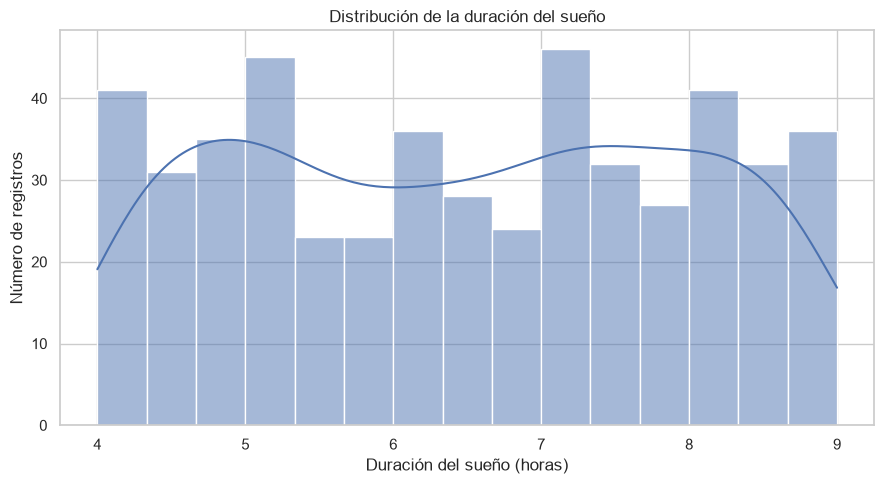

In [10]:
plt.figure(figsize=(9, 5))
sns.histplot(data=df_analysis, x="Sleep_Duration", bins=15, kde=True)
plt.title("Distribución de la duración del sueño")
plt.xlabel("Duración del sueño (horas)")
plt.ylabel("Número de registros")
plt.tight_layout()
plt.show()

### 6.2 Distribución de la calidad del sueño

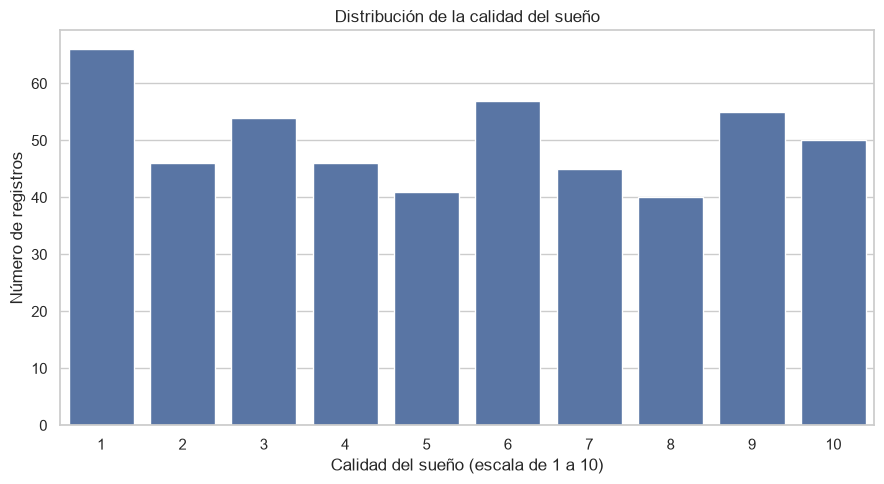

In [11]:
plt.figure(figsize=(9, 5))
sns.countplot(data=df_analysis, x="Sleep_Quality")
plt.title("Distribución de la calidad del sueño")
plt.xlabel("Calidad del sueño (escala de 1 a 10)")
plt.ylabel("Número de registros")
plt.tight_layout()
plt.show()

## 7. Análisis de correlación

Se utiliza Spearman para explorar asociaciones entre las variables numéricas seleccionadas.

In [12]:
correlation_columns = [
    "Sleep_Duration",
    "Study_Hours",
    "Screen_Time",
    "Caffeine_Intake",
    "Physical_Activity",
    "Sleep_Quality",
]

correlation_matrix = df_analysis[correlation_columns].corr(method="spearman")
display(correlation_matrix.round(3))

,Sleep_Duration,Study_Hours,Screen_Time,Caffeine_Intake,Physical_Activity,Sleep_Quality
Sleep_Duration,1.000,-0.010,0.071,-0.013,-0.005,-0.015
Study_Hours,-0.010,1.000,-0.041,0.033,-0.047,0.058
Screen_Time,0.071,-0.041,1.000,0.050,-0.037,0.010
Caffeine_Intake,-0.013,0.033,0.050,1.000,-0.027,-0.006
Physical_Activity,-0.005,-0.047,-0.037,-0.027,1.000,-0.014
Sleep_Quality,-0.015,0.058,0.010,-0.006,-0.014,1.000


### 7.1 Matriz de correlación

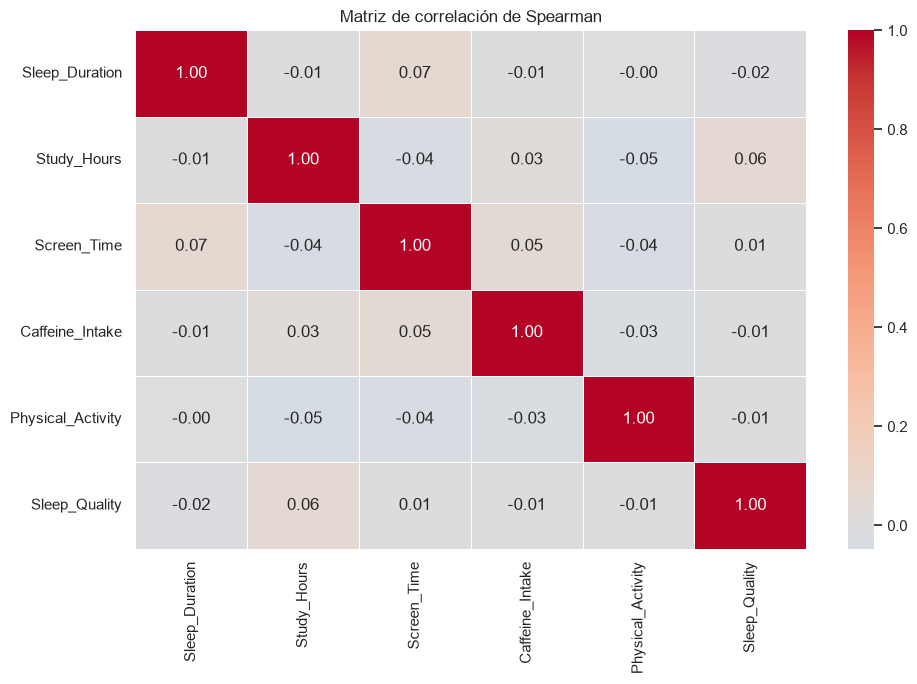

In [13]:
plt.figure(figsize=(10, 7))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f",
    linewidths=0.5,
)
plt.title("Matriz de correlación de Spearman")
plt.tight_layout()
plt.show()

### 7.2 Duplas de variables con mayor correlación absoluta

In [14]:
correlation_pairs = (
    correlation_matrix
    .where(np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool))
    .stack()
    .reset_index()
)
correlation_pairs.columns = ["Variable_1", "Variable_2", "Correlation"]
correlation_pairs["Absolute_Correlation"] = correlation_pairs["Correlation"].abs()
correlation_pairs = correlation_pairs.sort_values(
    "Absolute_Correlation", ascending=False
)
display(correlation_pairs.round(3))

,Variable_1,Variable_2,Correlation,Absolute_Correlation
2,Sleep_Duration,Screen_Time,0.071,0.071
11,Study_Hours,Sleep_Quality,0.058,0.058
15,Screen_Time,Caffeine_Intake,0.050,0.050
10,Study_Hours,Physical_Activity,-0.047,0.047
8,Study_Hours,Screen_Time,-0.041,0.041
16,Screen_Time,Physical_Activity,-0.037,0.037
9,Study_Hours,Caffeine_Intake,0.033,0.033
22,Caffeine_Intake,Physical_Activity,-0.027,0.027
5,Sleep_Duration,Sleep_Quality,-0.015,0.015
29,Physical_Activity,Sleep_Quality,-0.014,0.014


## 8. Comparación entre grupos

Se comparan variables de sueño entre grupos definidos por consumo de cafeína, actividad física y año universitario. Los gráficos muestran distribuciones y promedios; por sí solos no permiten establecer causas.

### 8.1 Calidad del sueño según consumo diario de cafeína

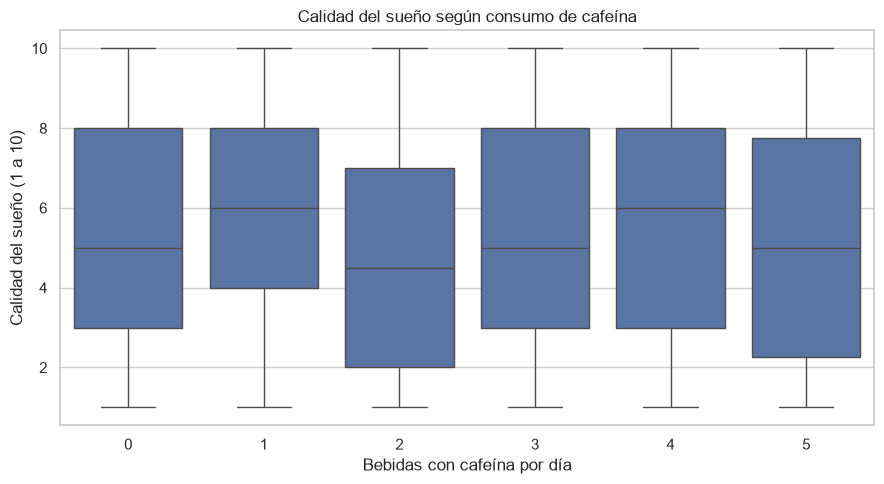

In [15]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=df_analysis, x="Caffeine_Intake", y="Sleep_Quality")
plt.title("Calidad del sueño según consumo de cafeína")
plt.xlabel("Bebidas con cafeína por día")
plt.ylabel("Calidad del sueño (1 a 10)")
plt.tight_layout()
plt.show()

El diagrama de caja permite comparar la mediana, la dispersión y los posibles valores extremos de la calidad del sueño para cada cantidad de bebidas con cafeína.

### 8.2 Duración del sueño según nivel de actividad física

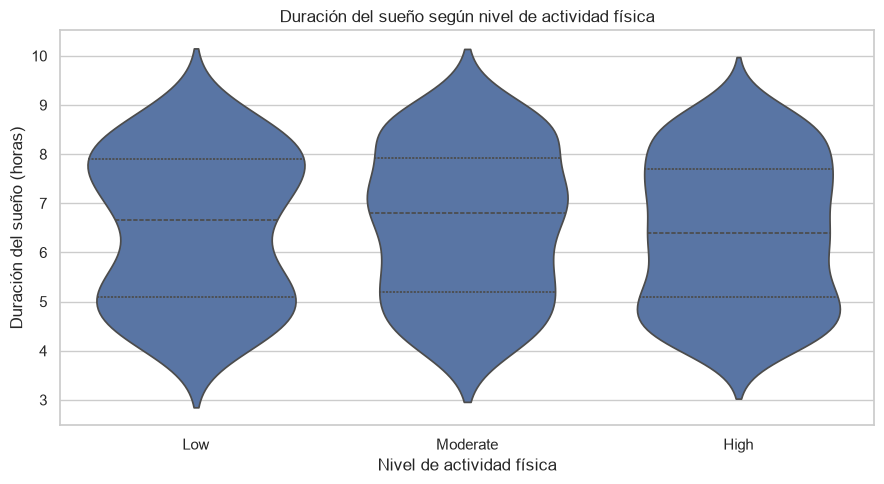

In [23]:
activity_order = ["Low", "Moderate", "High"]

plt.figure(figsize=(9, 5))
sns.violinplot(
    data=df_analysis,
    x="Physical_Activity_Category",
    y="Sleep_Duration",
    order=activity_order,
    inner="quartile",
)
plt.title("Duración del sueño según nivel de actividad física")
plt.xlabel("Nivel de actividad física")
plt.ylabel("Duración del sueño (horas)")
plt.tight_layout()
plt.show()

El gráfico de violín permite observar la forma de la distribución en cada grupo; las líneas interiores muestran los cuartiles.

### 8.3 Calidad promedio del sueño según año universitario

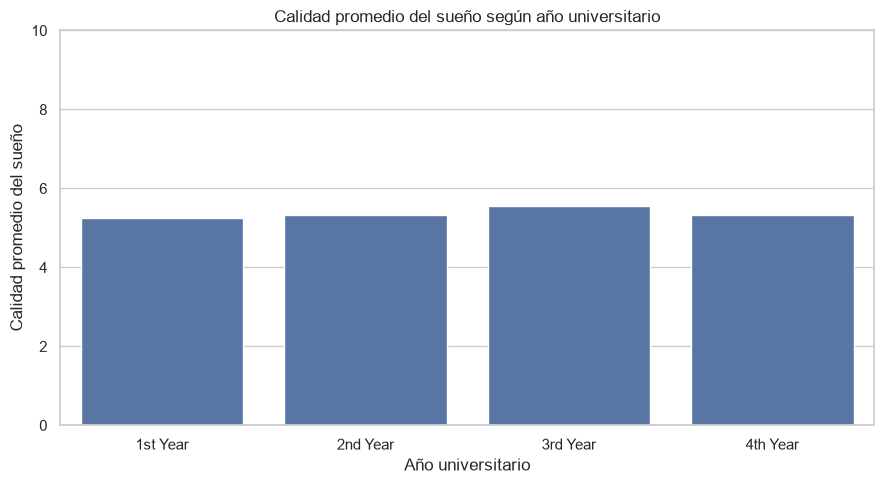

,Average_Sleep_Quality
University_Year,
1st Year,5.24
2nd Year,5.32
3rd Year,5.55
4th Year,5.33


In [17]:
year_order = ["1st Year", "2nd Year", "3rd Year", "4th Year"]

sleep_quality_by_year = (
    df_analysis.groupby("University_Year")["Sleep_Quality"]
    .mean()
    .reindex(year_order)
)

plt.figure(figsize=(9, 5))
sns.barplot(x=sleep_quality_by_year.index, y=sleep_quality_by_year.values)
plt.title("Calidad promedio del sueño según año universitario")
plt.xlabel("Año universitario")
plt.ylabel("Calidad promedio del sueño")
plt.ylim(0, 10)
plt.tight_layout()
plt.show()

display(sleep_quality_by_year.rename("Average_Sleep_Quality").round(2).to_frame())

## 9. Pruebas estadísticas

Se realizan pruebas complementarias para evaluar si las asociaciones o diferencias observadas cuentan con evidencia estadística. Se utiliza un nivel de significancia de 0.05.

### 9.1 Correlación de Spearman con la calidad del sueño

Se calcula el coeficiente y el valor p para cada variable seleccionada en relación con `Sleep_Quality`.

In [18]:
variables = [
    "Sleep_Duration",
    "Study_Hours",
    "Screen_Time",
    "Caffeine_Intake",
    "Physical_Activity",
]

correlation_test_results = []

for variable in variables:
    coefficient, p_value = stats.spearmanr(
        df_analysis[variable],
        df_analysis["Sleep_Quality"],
    )
    correlation_test_results.append({
        "Variable": variable,
        "Spearman_Correlation": coefficient,
        "P_Value": p_value,
        "Significant_at_0.05": p_value < 0.05,
    })

correlation_test_results = pd.DataFrame(correlation_test_results)
display(correlation_test_results.round(4))

,Variable,Spearman_Correlation,P_Value,Significant_at_0.05
0,Sleep_Duration,-0.0152,0.7340,False
1,Study_Hours,0.0583,0.1933,False
2,Screen_Time,0.0101,0.8217,False
3,Caffeine_Intake,-0.0063,0.8880,False
4,Physical_Activity,-0.0135,0.7629,False


### 9.2 Comparación de calidad del sueño según actividad física

Se utiliza la prueba de Kruskal-Wallis para comparar la distribución de las puntuaciones de calidad del sueño entre los tres niveles de actividad física. La prueba contrasta la hipótesis nula de que los grupos proceden de distribuciones con la misma localización.

In [19]:
activity_quality_groups = [
    group["Sleep_Quality"].dropna().to_numpy()
    for _, group in df_analysis.groupby(
        "Physical_Activity_Category", observed=True
    )
]

kw_statistic, kw_p_value = stats.kruskal(*activity_quality_groups)

print(f"Estadístico de Kruskal-Wallis: {kw_statistic:.4f}")
print(f"Valor p: {kw_p_value:.4f}")

if kw_p_value < 0.05:
    print("Se encontraron diferencias estadísticamente significativas entre al menos dos grupos.")
else:
    print("No se encontró evidencia suficiente de diferencias estadísticamente significativas entre los grupos.")

Estadístico de Kruskal-Wallis: 0.4129
Valor p: 0.8135
No se encontró evidencia suficiente de diferencias estadísticamente significativas entre los grupos.


## 10. Comparación de Pandas y Polars

Se carga el mismo archivo con Polars y se compara el número de filas y columnas, así como el promedio de duración del sueño. La comparación permite observar dos herramientas de manipulación de datos aplicadas a una misma fuente.

In [20]:
df_polars = pl.read_csv(str(DATA_PATH))

print("Dimensiones con Pandas:", df.shape)
print("Dimensiones con Polars:", df_polars.shape)

pandas_mean = df["Sleep_Duration"].mean()
polars_mean = df_polars.select(
    pl.col("Sleep_Duration").mean()
).item()

print(f"Promedio con Pandas: {pandas_mean:.4f}")
print(f"Promedio con Polars: {polars_mean:.4f}")
print("Los promedios coinciden:", np.isclose(pandas_mean, polars_mean))

Dimensiones con Pandas: (500, 14)
Dimensiones con Polars: (500, 14)
Promedio con Pandas: 6.4724
Promedio con Polars: 6.4724
Los promedios coinciden: True


## 11. Visualización interactiva con Bokeh

El siguiente diagrama de dispersión permite explorar la relación entre las horas de estudio y la duración del sueño. Al pasar el cursor sobre los puntos se muestran también la calidad del sueño y el tiempo frente a pantallas de cada registro.

In [21]:
source = ColumnDataSource(data={
    "study_hours": df_analysis["Study_Hours"],
    "sleep_duration": df_analysis["Sleep_Duration"],
    "sleep_quality": df_analysis["Sleep_Quality"],
    "screen_time": df_analysis["Screen_Time"],
})

interactive_plot = figure(
    title="Horas de estudio y duración del sueño",
    x_axis_label="Horas de estudio por día",
    y_axis_label="Duración del sueño (horas)",
    width=800,
    height=450,
    tools="pan,wheel_zoom,box_zoom,reset,save",
)

interactive_plot.add_tools(HoverTool(tooltips=[
    ("Horas de estudio", "@study_hours"),
    ("Duración del sueño", "@sleep_duration"),
    ("Calidad del sueño", "@sleep_quality"),
    ("Tiempo de pantalla", "@screen_time"),
]))

interactive_plot.scatter(
    x="study_hours",
    y="sleep_duration",
    source=source,
    size=8,
    alpha=0.6,
)

show(interactive_plot)

## 12. Conclusiones y limitaciones

El conjunto de datos contiene 500 registros y 14 variables iniciales, a las cuales se incorporan cuatro variables derivadas, obteniendo como resultado que, el DataFrame cuenta con 18 columnas.

La duración promedio del sueño es de **6.47 horas**, mientras que la calidad promedio registrada es de **5.36 puntos sobre 10**. En la clasificación utilizada, **286 registros (57.2 %) corresponden a menos de 7 horas de sueño** y 214 (42.8 %) se ubican entre 7 y 9 horas.

Las correlaciones de Spearman entre la calidad del sueño y las horas de estudio, el tiempo de pantalla, el consumo de cafeína, la actividad física y la duración del sueño son muy cercanas a cero. En las pruebas realizadas, sus valores p son superiores a 0.05; por tanto, no se encontró evidencia estadística suficiente de asociaciones monotónicas con la calidad del sueño en este conjunto de datos.

La prueba de Kruskal-Wallis tampoco detectó diferencias estadísticamente significativas en la calidad del sueño entre los grupos de actividad física (valor p aproximado de 0.8135).


## 13. Referencias

Bokeh Development Team. (s. f.). *Bokeh documentation*. https://docs.bokeh.org/

Consensus Conference Panel. (2015). Recommended amount of sleep for a healthy adult: A joint consensus statement of the American Academy of Sleep Medicine and Sleep Research Society. *Journal of Clinical Sleep Medicine, 11*(6), 591–592. https://doi.org/10.5664/jcsm.4758

Heckert, N. A., & Filliben, J. J. (2003). *NIST/SEMATECH e-Handbook of statistical methods: Exploratory data analysis*. National Institute of Standards and Technology. https://www.itl.nist.gov/div898/handbook/eda/eda.htm

Matplotlib Development Team. (s. f.). *Matplotlib documentation*. https://matplotlib.org/stable/

Polars. (s. f.). *Polars user guide*. https://docs.pola.rs/

SciPy Community. (s. f.). *scipy.stats.kruskal*. https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.kruskal.html

SciPy Community. (s. f.). *scipy.stats.spearmanr*. https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.spearmanr.html

Spearman, C. (1904). The proof and measurement of correlation between two things. *The American Journal of Psychology, 15*(1), 72–101. https://doi.org/10.2307/1412159

The pandas development team. (s. f.). *pandas documentation*. https://pandas.pydata.org/docs/

Tukey, J. W. (1977). *Exploratory data analysis*. Addison-Wesley.

University of Kentucky Libraries. (s. f.). *Common types of data visualizations*. https://libguides.uky.edu/data_applications/common_data_visualizations

Waskom, M. L. (2021). seaborn: Statistical data visualization. *Journal of Open Source Software, 6*(60), 3021. https://doi.org/10.21105/joss.03021

Watson, N. F., Badr, M. S., Belenky, G., Bliwise, D. L., Buxton, O. M., Buysse, D., Dinges, D. F., Gangwisch, J., Grandner, M. A., Kushida, C., Malhotra, R. K., Martin, J. L., Patel, S. R., Quan, S. F., & Tasali, E. (2015). Recommended amount of sleep for a healthy adult: A joint consensus statement of the American Academy of Sleep Medicine and Sleep Research Society. *Sleep, 38*(6), 843–844. https://doi.org/10.5665/sleep.4716

Yale University Library. (s. f.). *Common types of data visualizations*. https://guides.library.yale.edu/datavisualization/types
